<a href="https://colab.research.google.com/github/Krzyker/DataScienceColabs/blob/main/cse351_hw4_brachowski_krzysztof_116565000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Weather and Energy Usage Prediction Project**

Krzysztof Brachowski

---
This assignment uses data from [energy_data.cvs](energy_data.csv) and [weather_data.csv](weather_data.csv).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ed = pd.read_csv('/content/energy_data.csv')
wd = pd.read_csv('/content/weather_data.csv')
print(ed.columns.tolist())
print(ed.head(3))
print(wd.columns.tolist())
print(wd.head(3))

['Date & Time', 'use [kW]', 'gen [kW]', 'Grid [kW]', 'AC [kW]', 'Furnace [kW]', 'Cellar Lights [kW]', 'Washer [kW]', 'First Floor lights [kW]', 'Utility Rm + Basement Bath [kW]', 'Garage outlets [kW]', 'MBed + KBed outlets [kW]', 'Dryer + egauge [kW]', 'Panel GFI (central vac) [kW]', 'Home Office (R) [kW]', 'Dining room (R) [kW]', 'Microwave (R) [kW]', 'Fridge (R) [kW]']
           Date & Time  use [kW]  gen [kW]  Grid [kW]   AC [kW]  Furnace [kW]  \
0  2014-01-01 00:00:00  0.304439       0.0   0.304439  0.000058      0.009531   
1  2014-01-01 00:30:00  0.656771       0.0   0.656771  0.001534      0.364338   
2  2014-01-01 01:00:00  0.612895       0.0   0.612895  0.001847      0.417989   

   Cellar Lights [kW]  Washer [kW]  First Floor lights [kW]  \
0            0.005336     0.000126                 0.011175   
1            0.005522     0.000043                 0.003514   
2            0.005504     0.000044                 0.003528   

   Utility Rm + Basement Bath [kW]  Garage outle

We can obtain per day energy usage by summing the use field and merge it with the weather data. Before doing this, we need to standardize time across the two tables.

In [2]:
# Matching up the times
ed['Date & Time'] = pd.to_datetime(ed['Date & Time'])
ed['date'] = ed['Date & Time'].dt.normalize()

wd['time'] = pd.to_datetime(wd['time'], unit = 's')
wd['date'] = wd['time'].dt.normalize()

# Summing energy usage
daily_ed = ed.groupby('date', as_index=False)['use [kW]'].sum()
daily_wd = wd.groupby('date', as_index=False).mean(numeric_only=True)

merged = pd.merge(daily_ed, daily_wd, on='date')
print(merged.shape)
merged.head(10)

(365, 12)


,date,use [kW],temperature,humidity,visibility,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability
0,2014-01-01,65.013592,20.110833,0.556667,9.970000,1025.395000,6.820417,0.031304,252.291667,0.000000,6.362083,0.000000
1,2014-01-02,32.305336,16.382500,0.784583,3.834583,1023.465833,7.433750,0.354444,53.458333,0.002004,10.737083,0.074583
2,2014-01-03,31.164468,6.256667,0.680833,4.509167,1014.428750,12.828333,0.186364,207.333333,0.002029,-2.337500,0.080000
3,2014-01-04,45.287782,2.711667,0.617083,9.822917,1030.096250,5.248333,0.001667,240.166667,0.000000,-8.352083,0.000000
4,2014-01-05,36.316643,17.654167,0.682083,9.134583,1025.275000,3.417083,0.010952,208.958333,0.000033,8.615000,0.000417
5,2014-01-06,23.344397,39.084167,0.900417,4.062917,1003.460833,7.355833,1.000000,167.458333,0.026258,36.336250,0.460000
6,2014-01-07,27.108372,13.882917,0.481250,9.784167,1009.740000,14.787083,0.014348,284.500000,0.000000,-2.297917,0.000000
7,2014-01-08,34.440174,9.087917,0.504167,9.998750,1028.058333,7.298333,0.000833,228.750000,0.000000,-5.790417,0.000000
8,2014-01-09,26.693187,18.169583,0.570833,9.967083,1033.970000,4.840833,0.016957,255.208333,0.000000,5.136667,0.000000
9,2014-01-10,23.752311,20.532500,0.843750,7.059167,1033.154167,2.637500,0.160769,191.125000,0.001350,16.584583,0.054583


Now, we need to predict the usage for each day of the month of December we will start by splitting the dataset into training and testing data. We will split the data such that we train on all months but December, and test on December.

In [3]:
train_data = merged[merged['date'].dt.month != 12].copy()
test_data = merged[merged['date'].dt.month == 12].copy()

# Separating features from target
x_train = train_data[[col for col in daily_wd.columns if col != 'date']]
x_test = test_data[[col for col in daily_wd.columns if col != 'date']]

y_train = train_data['use [kW]']
y_test = test_data['use [kW]']

# **Linear Regression**
---
In this section, we will set up a simple linear regression model to train and predict energy usage in the month of December, and evaluate it using root mean squared error.

In [4]:
# Need scikit-learn packages
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Setting up the model
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)

y_pred = lr_model.predict(x_test)

Now we evaluate.

RMSE: 8.7406 kW


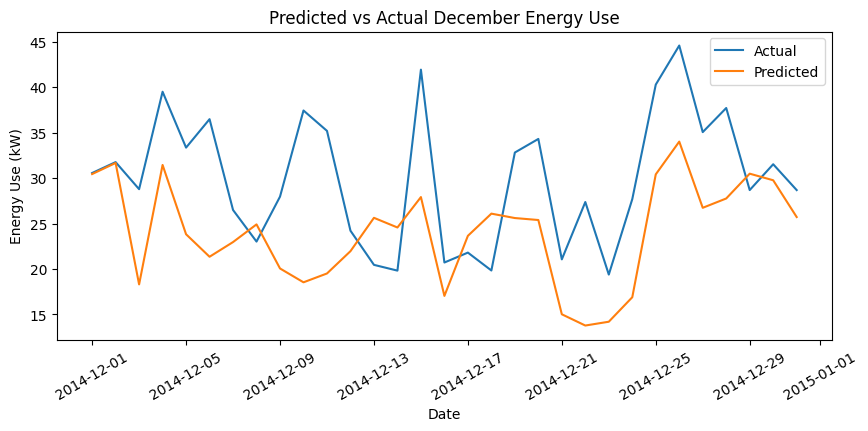

In [5]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"RMSE: {rmse:.4f} kW")

# Visualizing the data to get a better understanding of accuracy
plt.figure(figsize=(10,4))
plt.plot(test_data['date'], y_test.values, label='Actual')
plt.plot(test_data['date'], y_pred, label='Predicted')
plt.title('Predicted vs Actual December Energy Use')
plt.xlabel('Date')
plt.ylabel('Energy Use (kW)')
plt.xticks(rotation=30) #goated
plt.legend()
plt.show()

The Linear Regression model is clearly not great at estimating December energy use. The model almost always underestimates the energy use, irrespective of the date. December exhibits higher energy use as it is one of the coldest months, but hot months also exhibit higher energy usage because of AC. Thus, my hypothesis is that it is difficult for a linear regression model to estimate this non-linear trend, and therefore it fails at the extremes, like December. The RMSE of 8.74 kW assures that the model is not great at predicting this month.

In [6]:
# Generating a CSV dump of the predicted values

# Format of CSV file and where data is from
predictions_data = pd.DataFrame({'date': test_data['date'].dt.strftime('%Y-%m-%d').values, 'predicted_use_kW': y_pred})

predictions_data.to_csv('cse351_hw4_krzysztof_brachowski_116565000_linear_regression.csv', index=False)
predictions_data.head()

,date,predicted_use_kW
0,2014-12-01,30.434573
1,2014-12-02,31.655605
2,2014-12-03,18.306381
3,2014-12-04,31.435899
4,2014-12-05,23.818158


# **Logistic Regression**
---
In this section, we will set up a logistic regression model to classify whether the temperature in each month of december is low or high based on weather data.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# These two are for scaling features
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

y_train2 = (train_data['temperature'] >= 35).astype(int)
y_test2 = (test_data['temperature'] >= 35).astype(int)

# Dropping temp
features = [col for col in daily_wd.columns if col != 'date' and col != 'temperature']

x_train2 = train_data[features]
x_test2 = test_data[features]

Running the model and calculating F1 score.

In [12]:
log_model = make_pipeline(StandardScaler(), LogisticRegression())
log_model.fit(x_train2, y_train2)

y_pred2 = log_model.predict(x_test2)

# Eval
f1 = f1_score(y_test2, y_pred2)
print(f"F1 score: {f1:.4f}")

F1 score: 0.7273


An F1 score of **0.7273** means that the model did a pretty good job at classifying whether the days are hot or cold. Now, we generate the CSV dump.

In [13]:
# Generating a CSV dump of the predicted values

# Format of CSV file and where data is from
predictions_data = pd.DataFrame({'date': test_data['date'].dt.strftime('%Y-%m-%d').values, 'classification': y_pred2})

predictions_data.to_csv('cse351_hw4_krzysztof_brachowski_116565000_logistic_regression.csv', index=False)
predictions_data.head()

,date,classification
0,2014-12-01,1
1,2014-12-02,1
2,2014-12-03,1
3,2014-12-04,1
4,2014-12-05,0


# **Energy Usage Data Analysis**
---
We want to analyze how different devices are used throughout the day. To start, we will analyze if the washer is only used during the day, and during what time of day is the AC used most.  